# Validating the `root.hs3` plug-in

This notebook validates `root.hs3`, the [HS3](https://hep-statistics-serialization-standard.github.io/)
backend of [`spey-roofit`](https://github.com/SpeysideHEP/spey-roofit).

HS3 — the *HEP Statistics Serialization Standard* — describes a binned likelihood as a
plain JSON document, independently of the software that evaluates it. `root.hs3` compiles
such a document into a `RooFit` workspace with `RooJSONFactoryWSTool` and then hands it to
exactly the same machinery that `root.roofit` uses. The region structure of the document
and the injection of a signal are handled by the interpreter of
[`spey-hs3`](https://github.com/SpeysideHEP/spey-hs3), which works on the document itself,
so the user never has to touch `RooFit`.

The validation proceeds on four fronts:

1. **Against `spey`'s own likelihoods.** Three HS3 documents are written by hand so that
   they are *mathematically identical* to `default.uncorrelated_background`,
   `default.correlated_background` and `default.poisson`. Every number has to match.
2. **The distribution of the test statistic.** Toys drawn from the model are used to check
   that $t_\mu$ follows the $\chi^2_1$ distribution it should, and that `root.hs3` and
   `spey` give the *same* distribution.
3. **Expected exclusion.** The usual Brazilian plot, computed with both backends.
4. **Against a published analysis.** The ATLAS $t\bar{t}\gamma$ measurement, which HEPData
   publishes both as HS3 and as a `pyhf` workspace.

> The material for part 4 is not committed. Run `./download.sh` in this directory first;
> the notebook skips those sections cleanly if it is missing.

In [1]:
import json
import os
import sys
import time

import numpy as np
import spey
from spey.system.logger import disable_logging

import spey_roofit
from spey_roofit import HS3Interface, compile_workspace, load_document
from spey_roofit.hs3 import complete_model_config, repair_document

def find_repository(start=None):
    """Walk up from `start` until the directory holding pyproject.toml is found."""
    directory = os.path.abspath(start or os.getcwd())
    while True:
        if os.path.exists(os.path.join(directory, "pyproject.toml")):
            return directory
        parent = os.path.dirname(directory)
        if parent == directory:
            raise RuntimeError("run this notebook from inside the repository")
        directory = parent


REPOSITORY = find_repository()
TOPQ = os.path.join(REPOSITORY, "atlas-topq-2018-24")
sys.path.insert(0, os.path.join(REPOSITORY, "tests"))

TOPQ_AVAILABLE = os.path.exists(os.path.join(TOPQ, "workspace_dilep_1NF_HS3.json"))

# The pyhf comparison needs both the twin workspace and the spey-pyhf plug-in.
try:
    import spey_pyhf

    SPEY_PYHF = spey_pyhf.__version__
except ImportError:
    SPEY_PYHF = None
PYHF_TWIN_AVAILABLE = SPEY_PYHF is not None and os.path.exists(
    os.path.join(TOPQ, "workspace_dilep_1NF.json")
)

print("spey        ", spey.version())
print("spey-roofit ", spey_roofit.__version__)
print("spey-pyhf   ", SPEY_PYHF or "not installed")
print("ROOT        ", spey_roofit.manager.version)
print("backends    ", sorted(n for n in spey.AvailableBackends() if "root" in n or n == "pyhf"))
print()
print("ATLAS HS3 workspaces :", "available" if TOPQ_AVAILABLE else "MISSING - run ./download.sh")
print("their pyhf twins     :", "available" if PYHF_TWIN_AVAILABLE else "MISSING")

Spey - WARNING: An unstable version of Spey (0.2.8-b1) is being used. Latest stable version is 0.2.7.


spey         0.2.8-b1
spey-roofit  0.0.1
spey-pyhf    0.2.2


ROOT         6.36.04
backends     ['pyhf', 'root.hs3', 'root.roofit']

ATLAS HS3 workspaces : available
their pyhf twins     : available


---
## 1. What an HS3 document looks like

An HS3 document is a JSON object with a handful of top-level sections. The two that
matter for a binned analysis are `distributions`, which holds one `histfactory_dist` per
region, and `data`, which holds the observed counts.

The builders in `tests/hs3_models.py` write such a document from scratch. Here is the
twin of `spey`'s `default.uncorrelated_background`: one region, three bins, a background
sample carrying one `histosys` per bin — up and down templates $b_i\pm\sigma_i$, so that
`HistFactory`'s piecewise-linear interpolation gives exactly $b_i+\theta_i\sigma_i$ — and
a signal sample scaled by a `normfactor` $\mu$.

In [2]:
from hs3_models import (
    correlated_background_document,
    poisson_document,
    uncorrelated_background_document,
)

background = [50.0, 60.0, 30.0]
signal = [12.0, 11.0, 5.0]
uncertainty = [3.0, 5.0, 2.0]
observed = [51.0, 48.0, 32.0]
covariance = [[9.0, 2.0, 1.0], [2.0, 25.0, 3.0], [1.0, 3.0, 4.0]]

document = uncorrelated_background_document(background, signal, observed, uncertainty)

print("sections:", ", ".join(sorted(document)))
print()
# Show the model with only the first histosys kept, so the cell stays readable.
preview = json.loads(json.dumps(document))
distribution = preview["distributions"][0]
distribution["samples"][0]["modifiers"] = distribution["samples"][0]["modifiers"][:1] + ["..."]
print(json.dumps(preview["distributions"], indent=1))

sections: analyses, data, distributions, domains, likelihoods, metadata, parameter_points

[
 {
  "type": "histfactory_dist",
  "name": "model_ch",
  "axes": [
   {
    "name": "obs_x_ch",
    "min": 0.0,
    "max": 3.0,
    "nbins": 3
   }
  ],
  "samples": [
   {
    "name": "bkg",
    "data": {
     "contents": [
      50.0,
      60.0,
      30.0
     ]
    },
    "modifiers": [
     {
      "type": "histosys",
      "name": "theta0",
      "parameter": "theta0",
      "constraint": "Gauss",
      "data": {
       "hi": {
        "contents": [
         53.0,
         60.0,
         30.0
        ]
       },
       "lo": {
        "contents": [
         47.0,
         60.0,
         30.0
        ]
       }
      }
     },
     "..."
    ]
   },
   {
    "name": "sig",
    "data": {
     "contents": [
      12.0,
      11.0,
      5.0
     ]
    },
    "modifiers": [
     {
      "type": "normfactor",
      "name": "mu",
      "parameter": "mu"
     }
    ]
   }
  ]
 }
]


### The interpreter

`spey-hs3`'s `WorkspaceInterpreter` is the user-facing view of the document: it lists the
regions, their binning, the samples and their yields, without requiring any knowledge of
HS3 — let alone of `RooFit`. It is also what injects a signal, which is how a published
background-only likelihood is reinterpreted.

In [3]:
from spey_hs3.helper_functions import WorkspaceInterpreter

interpreter = WorkspaceInterpreter(document)
print("regions and bins    :", interpreter.bin_map)
print("samples             :", interpreter.samples)
print("signal samples      :", interpreter.signal_samples)
print("parameters of interest:", interpreter.poi_parameters)
print("background yields   :", interpreter.expected_background_yields)
print("observed data       :", interpreter.observed_data)

regions and bins    : {'model_ch': 3}
samples             : {'model_ch': ['bkg', 'sig']}
signal samples      : {'model_ch': ['sig']}
parameters of interest: ['mu']
background yields   : {'model_ch': [50.0, 60.0, 30.0]}
observed data       : {'model_ch': [51.0, 48.0, 32.0]}


### Compiling it

`compile_workspace` turns the document into an ordinary `RooWorkspace`. Two corrections
are applied on the way, both needed for documents that current `ROOT` versions produce or
demand:

* `RooJSONFactoryWSTool` creates the constraint terms of a `histfactory_dist` on the fly
  but does **not** declare their global observables, so the model configuration it builds
  is incomplete. Without recovering them the data vector would be missing its entire
  auxiliary half, and Asimov datasets would be wrong.
* the reader looks up a domain named literally `default_domain` and aborts the process —
  with an uncatchable C++ exception — when the document names its domain anything else.

In [4]:
workspace, model_config = compile_workspace(document)

print("workspace      :", workspace.GetName())
print("model config   :", model_config.GetName())
print("pdf            :", model_config.GetPdf().ClassName(), model_config.GetPdf().GetName())
print("POI            :", [v.GetName() for v in model_config.GetParametersOfInterest()])
print("nuisances      :", [v.GetName() for v in model_config.GetNuisanceParameters()])
print("global obs.    :", [v.GetName() for v in model_config.GetGlobalObservables()])
print("datasets       :", [d.GetName() for d in workspace.allData()])

# Without the completion step the auxiliary measurements would simply be absent:
_, bare = compile_workspace(document, complete=False)
print()
print("global observables the reader declares on its own:",
      len(bare.GetGlobalObservables() or []), "of", len(model_config.GetGlobalObservables()))

workspace      : hs3_workspace
model config   : simPdf_obsData
pdf            : RooProdPdf model_ch
POI            : ['mu']
nuisances      : ['theta0', 'theta1', 'theta2']
global obs.    : ['nom_theta0', 'nom_theta1', 'nom_theta2']
datasets       : ['obsData_ch']



global observables the reader declares on its own: 0 of 3


---
## 2. Exact comparison with `spey`'s own likelihoods

### 2.1 Uncorrelated background

$$
\mathcal{L}(\mu,\theta)=\prod_i \mathrm{Pois}\!\left(n_i\,\middle|\,\mu s_i+b_i+\theta_i\sigma_i\right)
\cdot\prod_i \mathrm{Gauss}\!\left(0\,\middle|\,\theta_i,1\right)
$$

The comparison is made **point by point at fixed parameters**. That is the only way to
separate the structure of the likelihood from any convention about *which* dataset it is
evaluated on — a distinction that matters again in section 2.4.

In [5]:
hs3_model = spey.get_backend("root.hs3")(workspace=document, analysis="hs3")
reference = spey.get_backend("default.uncorrelated_background")(
    signal_yields=signal,
    background_yields=background,
    data=observed,
    absolute_uncertainties=uncertainty,
    analysis="spey",
)

mine = hs3_model.backend.get_logpdf_func()
theirs = reference.backend.get_logpdf_func()

rng = np.random.default_rng(7)
print(f"{'mu':>7} {'theta':>22} {'root.hs3':>16} {'spey':>16} {'|difference|':>14}")
worst = 0.0
for _ in range(8):
    pars = np.concatenate([[rng.uniform(-1.0, 3.0)], rng.normal(0.0, 1.2, 3)])
    a, b = mine(pars), theirs(pars)
    worst = max(worst, abs(a - b))
    print(f"{pars[0]:7.3f} {np.array2string(pars[1:], precision=2):>22} "
          f"{a:16.10f} {b:16.10f} {abs(a - b):14.2e}")
print(f"\nlargest difference over 8 parameter points: {worst:.2e}")

     mu                  theta         root.hs3             spey   |difference|
  1.500    [ 0.36 -0.33 -1.07]   -20.1410764703   -20.1410764703       0.00e+00
  0.201    [-1.19  0.07  1.61]   -15.1241306759   -15.1241306759       1.78e-15
  2.188    [-0.74  0.59  0.43]   -27.4283667380   -27.4283667380       3.55e-14
  0.019    [-1.12 -0.04  0.83]   -13.5993704193   -13.5993704193       3.38e-14
  2.982    [-0.55 -2.28 -1.55]   -32.0096471126   -32.0096471126       1.21e-13
 -0.139    [-0.28 -1.52  0.33]   -12.6807081536   -12.6807081536       1.78e-14
 -0.857    [-0.22 -3.02 -0.65]   -20.6792136114   -20.6792136114       1.48e-12
  1.517    [ 0.14 -1.84 -0.57]   -18.9152267770   -18.9152267770       7.82e-14

largest difference over 8 parameter points: 1.48e-12


### 2.2 Correlated background

`default.correlated_background` writes the constraint as a correlated Gaussian on
$\theta$. `HistFactory` has no such term, so the twin uses the uncorrelated basis: the
covariance is factorised as $\Sigma=LL^T$ and the columns of $L$ become `histosys`
templates,

$$
\lambda_i=\mu s_i+b_i+\sum_k L_{ik}z_k\ ,\qquad z_k\sim\mathrm{Gauss}(0,1)\ .
$$

This is the *same model* in different coordinates, so the two log-likelihoods differ by
the constant Jacobian $\tfrac12\log\det\rho$ and by nothing else. Every likelihood ratio —
and therefore every inference result — is untouched.

In [6]:
correlated = correlated_background_document(background, signal, observed, covariance)

sigma = np.asarray(covariance, dtype=float)
factor = np.linalg.cholesky(sigma)
scale = np.diag(np.sqrt(np.diag(sigma)))
correlation = np.linalg.inv(scale) @ sigma @ np.linalg.inv(scale)
jacobian = 0.5 * np.log(np.linalg.det(correlation))

hs3_correlated = spey.get_backend("root.hs3")(workspace=correlated, analysis="hs3")
spey_correlated = spey.get_backend("default.correlated_background")(
    signal_yields=signal,
    background_yields=background,
    data=observed,
    covariance_matrix=sigma,
    analysis="spey",
)
mine = hs3_correlated.backend.get_logpdf_func()
theirs = spey_correlated.backend.get_logpdf_func()

print(f"expected Jacobian  0.5 * log det(rho) = {jacobian:.12f}\n")
rng = np.random.default_rng(7)
for _ in range(5):
    poi = rng.uniform(-1.0, 2.0)
    latent = rng.normal(0.0, 1.0, 3)          # the z of the HS3 document
    theta = np.linalg.inv(scale) @ (factor @ latent)   # the theta of spey
    difference = mine(np.r_[poi, latent]) - theirs(np.r_[poi, theta])
    print(f"mu = {poi:6.3f}   difference = {difference:.12f}   "
          f"deviation from the Jacobian = {abs(difference - jacobian):.2e}")

print(f"\nfitted signal strength:  root.hs3 {hs3_correlated.maximize_likelihood()[0]:.6f}"
      f"   spey {spey_correlated.maximize_likelihood()[0]:.6f}")

expected Jacobian  0.5 * log det(rho) = -0.065180908932

mu =  0.875   difference = -0.065180908932   deviation from the Jacobian = 9.82e-14
mu = -0.100   difference = -0.065180908932   deviation from the Jacobian = 1.91e-14
mu =  1.391   difference = -0.065180908932   deviation from the Jacobian = 3.78e-14
mu = -0.235   difference = -0.065180908932   deviation from the Jacobian = 8.22e-14
mu =  1.987   difference = -0.065180908931   deviation from the Jacobian = 1.37e-13

fitted signal strength:  root.hs3 -0.233813   spey -0.233840


### 2.3 No nuisance parameters at all

A document whose only modifier is the signal strength has no constraint term, hence no
auxiliary data. This is `spey`'s `default.poisson`, and it exercises the `naux = 0` path.

In [7]:
poisson = poisson_document(background, signal, observed)
hs3_poisson = spey.get_backend("root.hs3")(workspace=poisson, analysis="hs3")
spey_poisson = spey.get_backend("default.poisson")(
    signal_yields=signal,
    background_yields=background,
    data=[int(value) for value in observed],
    analysis="spey",
)

print("bins:", hs3_poisson.backend.model.nbins,
      " auxiliary measurements:", hs3_poisson.backend.model.naux,
      " parameters:", hs3_poisson.backend.model.parameter_names)
print()
print(f"{'mu':>6} {'root.hs3':>16} {'spey':>16} {'|difference|':>14}")
for poi_test in (0.0, 0.5, 1.0, 2.0, 3.0):
    a, b = hs3_poisson.likelihood(poi_test), spey_poisson.likelihood(poi_test)
    print(f"{poi_test:6.1f} {a:16.10f} {b:16.10f} {abs(a - b):14.2e}")

print(f"\nCLs:  root.hs3 {hs3_poisson.exclusion_confidence_level()[0]:.10f}"
      f"   spey {spey_poisson.exclusion_confidence_level()[0]:.10f}")

bins: 3  auxiliary measurements: 0  parameters: ['mu']

    mu         root.hs3             spey   |difference|
   0.0     9.7614472122     9.7614472122       0.00e+00
   0.5    11.2104497558    11.2104497558       2.84e-14
   1.0    13.7778499859    13.7778499859       2.84e-14
   2.0    21.5674895351    21.5674895351       5.68e-14
   3.0    32.0917882359    32.0917882359       1.42e-14

CLs:  root.hs3 0.9928786774   spey 0.9928786774


### 2.4 Asimov data

An Asimov dataset has one defining property: refitting it returns the parameters it was
generated at. Eq. (25) of [arXiv:1007.1727](https://arxiv.org/abs/1007.1727) makes that
concrete — the auxiliary measurements have to *follow* the nuisance parameters, not sit at
the centre of the constraint, or the nuisance parameters do not come back.

`RooFit` does this, as `RooStats::AsymptoticCalculator::MakeAsimovData` and `pyhf` do.
`spey` did not, up to and including 0.2.7: its built-in backends emitted the auxiliary half
of the data vector and then discarded it. That is fixed in 0.2.8, and the cell below is
where the two would part company otherwise — it is worth keeping an eye on when comparing
against an older `spey`.

In [8]:
pars = [1.0, 0.3, -0.7, 0.2]
ours = np.asarray(hs3_model.backend.expected_data(pars))
spey_data = np.asarray(reference.backend.expected_data(pars))
nbins = hs3_model.backend.model.nbins

print("Asimov data generated at mu = 1, theta = (0.3, -0.7, 0.2)")
print(f"  bin counts   root.hs3 {np.round(ours[:nbins], 6)}")
print(f"               spey     {np.round(spey_data[:nbins], 6)}")
print(f"  auxiliary    root.hs3 {np.round(ours[nbins:], 6)}")
print(f"               spey     {np.round(spey_data[nbins:], 6)}")
print(f"  the auxiliary data follow theta: "
      f"{np.max(np.abs(ours[nbins:] - np.asarray(pars[1:]))):.1e} away from it")
print(f"  largest difference between the two backends: "
      f"{np.max(np.abs(ours - spey_data)):.1e}")

print("\nobserved exclusion and upper limit:")
print(f"  CLs        root.hs3 {hs3_model.exclusion_confidence_level()[0]:.10f}"
      f"   spey {reference.exclusion_confidence_level()[0]:.10f}")
print(f"  95% CL UL  root.hs3 {hs3_model.poi_upper_limit():.8f}"
      f"   spey {reference.poi_upper_limit():.8f}")

print("\nsigma_mu is the one quantity that still differs, and for a different reason:")
print(f"  root.hs3 {hs3_model.sigma_mu(1.0):.6f}   spey {reference.sigma_mu(1.0):.6f}")
print("  spey uses the analytic Hessian when a backend provides one, which RooFit does")
print("  not; root.hs3 therefore falls back to the asymptotic sigma_A = |mu - mu'| / sqrt(q_mu,A).")
print("  Two estimators of the same quantity, equal only in the asymptotic limit.")

Asimov data generated at mu = 1, theta = (0.3, -0.7, 0.2)
  bin counts   root.hs3 [62.9 67.5 35.4]
               spey     [62.9 67.5 35.4]
  auxiliary    root.hs3 [ 0.3 -0.7  0.2]
               spey     [ 0.3 -0.7  0.2]
  the auxiliary data follow theta: 0.0e+00 away from it
  largest difference between the two backends: 0.0e+00

observed exclusion and upper limit:
  CLs        root.hs3 0.9838873987   spey 0.9838874178


  95% CL UL  root.hs3 0.79047972   spey 0.79047952

sigma_mu is the one quantity that still differs, and for a different reason:
  root.hs3 0.484859   spey 0.537514
  spey uses the analytic Hessian when a backend provides one, which RooFit does
  not; root.hs3 therefore falls back to the asymptotic sigma_A = |mu - mu'| / sqrt(q_mu,A).
  Two estimators of the same quantity, equal only in the asymptotic limit.


---
## 3. The distribution of the test statistic

A likelihood is more than a number: the *distribution* of the test statistic it produces
is what turns a fit into a $p$-value. Wilks' theorem says that, for data generated at
$\mu$, the profile-likelihood test statistic

$$
t_\mu = -2\log\frac{\mathcal{L}(\mu,\hat{\hat\theta}_\mu)}{\mathcal{L}(\hat\mu,\hat\theta)}
$$

follows a $\chi^2_1$ distribution asymptotically.

The pseudo-data are drawn **once**, from the `root.hs3` sampler, and then evaluated with
both backends, so any difference between the two is in the likelihood rather than in the
random numbers. Each pseudo-dataset consists of the bin counts *and* the auxiliary
measurements, both of which fluctuate — so this exercises the same machinery as section 2.4
on data that actually moves.

In [9]:
from spey.optimizer.core import fit


def test_statistic(backend, data, poi_test):
    """Profile-likelihood test statistic t_mu for one pseudo-dataset."""
    config = backend.config(allow_negative_signal=True)
    logpdf = backend.get_logpdf_func(data=data)

    def negative(pars):
        return -logpdf(pars)

    conditional, _ = fit(
        func=negative, model_configuration=config, fixed_poi_value=poi_test
    )
    unconditional, _ = fit(func=negative, model_configuration=config)
    return 2.0 * (conditional - unconditional)


POI_TEST = 1.0
N_TOYS = 2000

truth = np.array([POI_TEST, 0.0, 0.0, 0.0])
sampler = hs3_model.backend.get_sampler(truth)
np.random.seed(20240923)
toys = sampler(N_TOYS)

start = time.time()
t_hs3 = np.array([test_statistic(hs3_model.backend, toy, POI_TEST) for toy in toys])
t_spey = np.array([test_statistic(reference.backend, toy, POI_TEST) for toy in toys])
print(f"{N_TOYS} toys through both backends in {time.time() - start:.1f} s")

finite = np.isfinite(t_hs3) & np.isfinite(t_spey)
print(f"usable toys: {finite.sum()} / {N_TOYS}")
print(f"largest |t_hs3 - t_spey|: {np.max(np.abs(t_hs3[finite] - t_spey[finite])):.2e}"
      f"   (optimiser tolerance, not model difference)")
print()
print(f"{'':<12} {'mean':>8} {'median':>8} {'90th pct':>9}")
print(f"{'chi2_1':<12} {1.0:>8.4f} {0.4549:>8.4f} {2.7055:>9.4f}")
print(f"{'root.hs3':<12} {t_hs3[finite].mean():>8.4f} {np.median(t_hs3[finite]):>8.4f} "
      f"{np.percentile(t_hs3[finite], 90):>9.4f}")
print(f"{'spey':<12} {t_spey[finite].mean():>8.4f} {np.median(t_spey[finite]):>8.4f} "
      f"{np.percentile(t_spey[finite], 90):>9.4f}")

2000 toys through both backends in 131.2 s
usable toys: 2000 / 2000
largest |t_hs3 - t_spey|: 1.54e-06   (optimiser tolerance, not model difference)

                 mean   median  90th pct
chi2_1         1.0000   0.4549    2.7055
root.hs3       1.0188   0.5150    2.6306
spey           1.0188   0.5150    2.6306


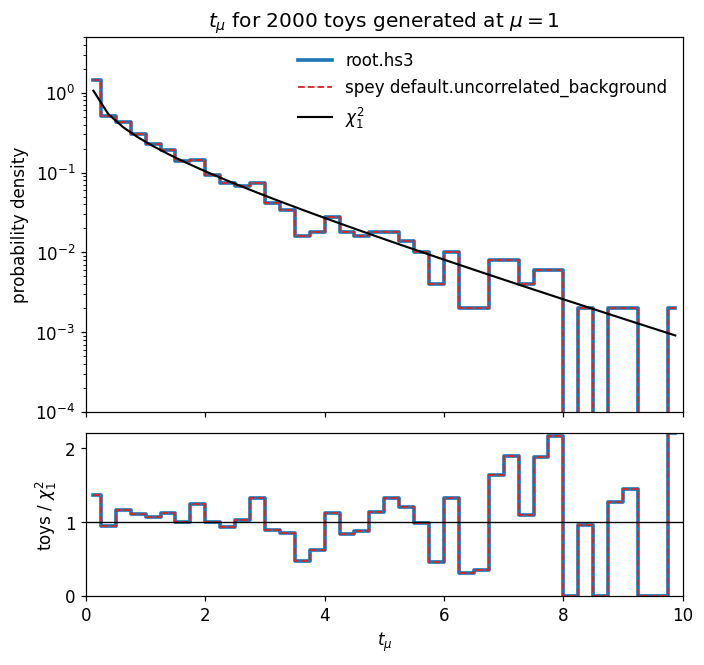

Kolmogorov-Smirnov against chi2_1:
  root.hs3   D = 0.0320   p = 0.032
  spey       D = 0.0320   p = 0.032


In [10]:
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({"figure.dpi": 110, "font.size": 11})

fig, (upper, lower) = plt.subplots(
    2, 1, figsize=(7.0, 6.6), sharex=True,
    gridspec_kw={"height_ratios": [3, 1.3], "hspace": 0.08},
)

edges = np.linspace(0.0, 10.0, 41)
centres = 0.5 * (edges[1:] + edges[:-1])
density_hs3, _ = np.histogram(t_hs3[finite], bins=edges, density=True)
density_spey, _ = np.histogram(t_spey[finite], bins=edges, density=True)
expected = stats.chi2.pdf(centres, df=1)

upper.step(centres, density_hs3, where="mid", lw=2.4, color="#1f77b4", label="root.hs3")
upper.step(centres, density_spey, where="mid", lw=1.2, ls="--", color="#d62728",
           label="spey default.uncorrelated_background")
upper.plot(centres, expected, color="k", lw=1.4, label=r"$\chi^2_1$")
upper.set_yscale("log")
upper.set_ylim(1e-4, 5.0)
upper.set_ylabel("probability density")
upper.set_title(rf"$t_\mu$ for {finite.sum()} toys generated at $\mu={POI_TEST:g}$")
upper.legend(frameon=False)

with np.errstate(divide="ignore", invalid="ignore"):
    ratio_hs3 = np.where(expected > 0, density_hs3 / expected, np.nan)
    ratio_spey = np.where(expected > 0, density_spey / expected, np.nan)
lower.step(centres, ratio_hs3, where="mid", lw=2.4, color="#1f77b4")
lower.step(centres, ratio_spey, where="mid", lw=1.2, ls="--", color="#d62728")
lower.axhline(1.0, color="k", lw=0.9)
lower.set_ylim(0.0, 2.2)
lower.set_ylabel(r"toys / $\chi^2_1$")
lower.set_xlabel(r"$t_\mu$")
lower.set_xlim(edges[0], edges[-1])

plt.show()

print("Kolmogorov-Smirnov against chi2_1:")
for label, values in (("root.hs3", t_hs3[finite]), ("spey", t_spey[finite])):
    result = stats.kstest(values, "chi2", args=(1,))
    print(f"  {label:<10} D = {result.statistic:.4f}   p = {result.pvalue:.3f}")

The two curves lie on top of each other — the red dashed line is `spey` drawn over the
blue `root.hs3` histogram — because they are the same likelihood evaluated on the same
pseudo-data. Their test statistics agree to $1.5\times10^{-6}$, which is the tolerance of
the minimiser, not a property of either model.

Both deviate from $\chi^2_1$ by the same, modest amount: the mean is 2% high, the median
sits at 0.515 against 0.455, and the Kolmogorov–Smirnov test gives $p\approx0.03$. That is
not a defect of either implementation. Wilks' theorem is asymptotic, and this model has
three bins with about fifty events each, so a deviation of this size is what one should
expect — the boundary at $\hat\mu$ and the finite counts both contribute. The point of the
comparison is that whatever the deviation is, the two backends reproduce it identically.

---
## 4. Expected exclusion: the Brazilian plot

The standard sensitivity summary: expected $\mathrm{CL}_s$ as a function of the signal
strength, with the $\pm1\sigma$ and $\pm2\sigma$ bands of the background-only expectation,
and the observed curve on top — computed twice, once with each backend.

In [11]:
scan = np.linspace(0.05, 2.0, 24)
apriori = spey.ExpectationType.apriori

start = time.time()
bands_hs3 = np.array([hs3_model.exclusion_confidence_level(poi_test=mu, expected=apriori)
                      for mu in scan])
bands_spey = np.array([reference.exclusion_confidence_level(poi_test=mu, expected=apriori)
                       for mu in scan])
observed_hs3 = np.array([hs3_model.exclusion_confidence_level(poi_test=mu)[0] for mu in scan])
observed_spey = np.array([reference.exclusion_confidence_level(poi_test=mu)[0] for mu in scan])
print(f"scanned {len(scan)} points with both backends in {time.time() - start:.1f} s")

limit_hs3 = hs3_model.poi_upper_limit(expected=apriori)
limit_spey = reference.poi_upper_limit(expected=apriori)
print(f"expected 95% CL upper limit on mu:  root.hs3 {limit_hs3:.6f}   spey {limit_spey:.6f}")
print(f"largest difference between the two expected medians: "
      f"{np.max(np.abs(bands_hs3[:, 2] - bands_spey[:, 2])):.2e}")

scanned 24 points with both backends in 5.6 s


expected 95% CL upper limit on mu:  root.hs3 0.953949   spey 0.953944
largest difference between the two expected medians: 2.48e-06


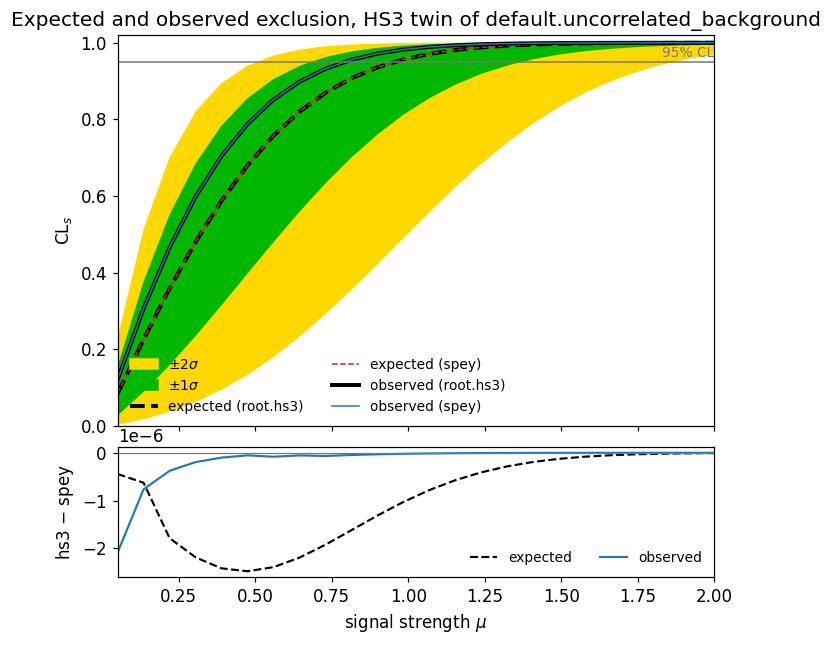

In [12]:
fig, (upper, lower) = plt.subplots(
    2, 1, figsize=(7.0, 6.4), sharex=True, gridspec_kw={"height_ratios": [3, 1], "hspace": 0.08}
)

# spey returns the bands ordered -2sigma, -1sigma, median, +1sigma, +2sigma.
upper.fill_between(scan, bands_hs3[:, 0], bands_hs3[:, 4], color="#FFD800", label=r"$\pm2\sigma$")
upper.fill_between(scan, bands_hs3[:, 1], bands_hs3[:, 3], color="#00B800", label=r"$\pm1\sigma$")
# The two backends overlap, so spey is drawn thin on top of a thick root.hs3 line.
upper.plot(scan, bands_hs3[:, 2], color="k", ls="--", lw=2.6, label="expected (root.hs3)")
upper.plot(scan, bands_spey[:, 2], color="#d62728", ls="--", lw=1.0, label="expected (spey)")
upper.plot(scan, observed_hs3, color="k", lw=2.6, label="observed (root.hs3)")
upper.plot(scan, observed_spey, color="#1f77b4", lw=1.0, label="observed (spey)")
upper.axhline(0.95, color="#777777", lw=1.0)
upper.text(scan[-1], 0.955, "95% CL", ha="right", va="bottom", color="#777777", fontsize=9)
upper.set_ylabel(r"$\mathrm{CL}_s$")
upper.set_ylim(0.0, 1.02)
upper.set_title("Expected and observed exclusion, HS3 twin of default.uncorrelated_background")
upper.legend(frameon=False, ncol=2, fontsize=9, loc="lower left")

lower.plot(scan, bands_hs3[:, 2] - bands_spey[:, 2], color="k", ls="--", lw=1.4,
           label="expected")
lower.plot(scan, observed_hs3 - observed_spey, color="#1f77b4", lw=1.4, label="observed")
lower.axhline(0.0, color="#777777", lw=0.8)
lower.set_xlabel(r"signal strength $\mu$")
lower.set_ylabel("hs3 $-$ spey")
lower.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
lower.legend(frameon=False, fontsize=9, ncol=2)
lower.set_xlim(scan[0], scan[-1])

plt.show()

The expected medians agree to $2.5\times10^{-6}$ in $\mathrm{CL}_s$ and the observed curves
to $2\times10^{-8}$; the expected upper limits, 0.953949 against 0.953944, agree to five
significant figures. What is left is the minimiser, not the model: the two log-likelihoods
agreed to $10^{-12}$ at fixed parameters in section 2.1.

---
## 5. The same model, two serialisations

The sharpest cross-check available without any external data: take a `HistFactory`
workspace, let `ROOT` export it to HS3, and read it back through `root.hs3`. Both
backends end up evaluating a `RooFit` model built from the same description, so the
agreement has to be *exact* rather than merely close.

The `repair_document` step exists for this path too: `ROOT` 6.36 writes the Gaussian
constraints of *some* `HistFactory` workspaces without the `x` key the standard requires,
producing documents its own reader rejects with `node '...Constraint' is missing key 'x'`.
The cell below reports how many of them this particular export needed.

In [13]:
from toy_models import uncorrelated_background_workspace
from spey_roofit.helper_functions import load_workspace

WORKDIR = os.path.join(REPOSITORY, "atlas-topq-2018-24", "_generated")
os.makedirs(WORKDIR, exist_ok=True)

root_path = uncorrelated_background_workspace(
    WORKDIR, background, signal, observed, uncertainty, name="roundtrip"
)
ROOT = spey_roofit.manager.ROOT
exported = json.loads(ROOT.RooJSONFactoryWSTool(load_workspace(root_path)).exportJSONtoString())
exported_path = os.path.join(WORKDIR, "roundtrip_HS3.json")
with open(exported_path, "w", encoding="utf-8") as handle:
    json.dump(exported, handle)

missing_x = [d["name"] for d in exported["distributions"]
             if d.get("type") == "gaussian_dist" and "x" not in d]
print(f"exported {os.path.getsize(exported_path) / 1024:.1f} kB of HS3")
print(f"constraints written without their 'x' key: {len(missing_x)}")

from_root = spey.get_backend("root.roofit")(workspace=root_path, analysis="root.roofit")
from_hs3 = spey.get_backend("root.hs3")(workspace=exported_path, analysis="root.hs3")

print(f"\nparameters  root.roofit {from_root.backend.model.parameter_names}")
print(f"            root.hs3    {from_hs3.backend.model.parameter_names}")

a, b = from_root.backend.get_logpdf_func(), from_hs3.backend.get_logpdf_func()
rng = np.random.default_rng(1)
differences = []
for _ in range(8):
    pars = np.concatenate([[rng.uniform(-0.5, 2.0)], rng.normal(0.0, 0.8, 3)])
    differences.append(abs(a(pars) - b(pars)))
print(f"\nlargest |log L difference| over 8 points: {max(differences):.1e}")
print(f"CLs   root.roofit {from_root.exclusion_confidence_level()[0]:.12f}")
print(f"      root.hs3    {from_hs3.exclusion_confidence_level()[0]:.12f}")

exported 5.6 kB of HS3
constraints written without their 'x' key: 0



parameters  root.roofit ['mu', 'alpha_theta0', 'alpha_theta1', 'alpha_theta2']
            root.hs3    ['mu', 'alpha_theta0', 'alpha_theta1', 'alpha_theta2']

largest |log L difference| over 8 points: 0.0e+00
CLs   root.roofit 0.983887397038
      root.hs3    0.983887397038


---
## 6. A published analysis: ATLAS $t\bar{t}\gamma$

> ATLAS Collaboration, *Measurements of inclusive and differential cross-sections of
> $t\bar{t}\gamma$ production in $pp$ collisions at $\sqrt{s}=13$ TeV with the ATLAS
> detector*, [arXiv:2403.09452](https://arxiv.org/abs/2403.09452), JHEP 10 (2024) 191,
> [HEPData ins2768921](https://www.hepdata.net/record/ins2768921).

The record publishes six likelihoods — single-lepton, dilepton and their combination,
each in an inclusive (`1NF`) and a production/decay-separated (`2NF`) variant — and it
publishes each of them **twice**, once as HS3 and once as a `pyhf` workspace. That is
what makes it useful here: the two files describe the same measurement in two independent
serialisations.

These are *measurement* likelihoods rather than searches, so the parameter of interest is
a cross-section signal strength that the data prefer near one, not an exclusion.

In [14]:
if not TOPQ_AVAILABLE:
    print("The ATLAS workspaces are not present. Run ./download.sh in this directory.")
else:
    from spey_roofit.hs3 import compile_workspace

    names = ["dilep_1NF", "dilep_2NF", "ljets_1NF", "ljets_2NF",
             "combined_1NF", "combined_2NF"]
    print(f"{'workspace':>14} {'channels':>9} {'bins':>5} {'parameters':>11} "
          f"{'auxiliary':>10} {'POI':>16}")
    structure = {}
    for name in names:
        path = os.path.join(TOPQ, f"workspace_{name}_HS3.json")
        model = spey.get_backend("root.hs3")(workspace=path, analysis=name)
        view = model.backend.model
        structure[name] = model
        print(f"{name:>14} {len(view.channels):>9} {view.nbins:>5} {view.npar:>11} "
              f"{view.naux:>10} {view.poi.GetName():>16}")

    combined = structure["combined_1NF"].backend.model
    print("\nchannels of the combined fit:", combined.bin_map)

     workspace  channels  bins  parameters  auxiliary              POI


     dilep_1NF         1    10         226        226    SigXsecOverSM


     dilep_2NF         1    10         226        225    SigXsecOverSM


     ljets_1NF         4    21         249        249    SigXsecOverSM


     ljets_2NF         4    21         249        248    SigXsecOverSM


  combined_1NF         5    31         271        271    SigXsecOverSM


  combined_2NF         5    31         271        270    SigXsecOverSM

channels of the combined fit: {'SR': 6, 'CR_tty_dec': 5, 'CR_fakes': 5, 'CR_photon': 5, 'SR_alt1': 10}


### What the interpreter shows

Everything a user needs in order to reinterpret one of these likelihoods — the regions,
their binning, which samples are signal — comes out of the document without touching
`RooFit`.

In [15]:
if TOPQ_AVAILABLE:
    document_dilep = load_document(os.path.join(TOPQ, "workspace_dilep_1NF_HS3.json"))
    view = WorkspaceInterpreter(document_dilep)

    print("regions and bins :", view.bin_map)
    print("POI              :", view.poi_parameters)
    print("signal samples   :", view.signal_samples)
    print()
    yields = view.expected_background_yields["model_SR_alt1"]
    data_counts = view.observed_data["model_SR_alt1"]
    print(f"{'bin':>4} {'background':>12} {'observed':>10}")
    for index, (b, n) in enumerate(zip(yields, data_counts)):
        print(f"{index:>4} {b:12.2f} {n:10.0f}")

regions and bins : {'model_SR_alt1': 10}
POI              : ['SigXsecOverSM']
signal samples   : {'model_SR_alt1': ['tty_LO_dec_SR_alt1_overallSyst_x_StatUncert', 'tty_NLO_prod_SR_alt1_overallSyst_x_StatUncert']}

 bin   background   observed
   0        95.22        327
   1       224.29       1160
   2       176.87       1063
   3       181.34        924
   4       207.14        876
   5       139.99        663
   6       122.97        592
   7       100.57        603
   8        80.02        567
   9        64.73        604


### Recovering the measured signal strength

The workspace was published after ATLAS fitted it, so the maximum-likelihood estimate
`spey` finds has to reproduce the measurement. The dilepton fit has 225 floating nuisance
parameters over ten bins; profiling them takes a few seconds per likelihood evaluation.

In [16]:
if TOPQ_AVAILABLE:
    dilep = structure["dilep_1NF"]
    start = time.time()
    muhat, nll = dilep.maximize_likelihood()
    elapsed = time.time() - start
    print(f"mu_hat = {muhat:.5f}   -log L = {nll:.5f}   ({elapsed:.1f} s)")

    start = time.time()
    sigma = dilep.sigma_mu(muhat)
    print(f"sigma_mu = {sigma:.5f}   ({time.time() - start:.1f} s)")
    print(f"\nmeasured signal strength: {muhat:.3f} +/- {sigma:.3f}")

mu_hat = 1.10989   -log L = 293.32962   (9.1 s)


sigma_mu = 0.09671   (46.1 s)

measured signal strength: 1.110 +/- 0.097


### Against the `pyhf` twin

The same fit, read from the `pyhf` serialisation of the same record — through the
[`spey-pyhf`](https://github.com/SpeysideHEP/spey-pyhf) plug-in rather than through `pyhf`
directly, so that both sides are asked the same questions by the same `spey` interface and
only the likelihood implementation differs.

Two things have to be lined up first. The parameters are **named** differently: `RooFit`
calls a nuisance parameter `alpha_BTag_B_0` and its Monte-Carlo statistics parameters
`gamma_stat_<region>_bin_k`, where `pyhf` calls them `BTag_B_0` and
`staterror_<region>[k]`. And they are **ordered** differently, so the vectors are matched
up by name. `pyhf` also carries a `lumi` parameter that the `RooFit` model holds constant
and never exposes; it has to keep the value `spey-pyhf` suggests for it rather than being
zeroed, or every expected yield is multiplied by nothing.

In [17]:
if TOPQ_AVAILABLE and PYHF_TWIN_AVAILABLE:
    import re

    import spey_pyhf

    # spey-pyhf picks the jax tensor backend whenever jax is importable. numpy is
    # pyhf's own reference implementation and has no platform-dependent precision,
    # which is what a number-by-number comparison wants.
    spey_pyhf.manager.backend = "numpy"
    print("pyhf tensor backend:", spey_pyhf.manager.backend)

    with open(os.path.join(TOPQ, "workspace_dilep_1NF.json"), encoding="utf-8") as handle:
        spec = json.load(handle)
    # An empty signal patch is deliberate: this workspace already carries its
    # signal, so there is nothing to add. spey-pyhf warns that no channel is
    # patched, and judges `is_alive` from the patch rather than from the model,
    # so it reports False here - which only matters for `poi_upper_limit`, and
    # this section compares likelihoods and yields rather than limits.
    with disable_logging():
        twin = spey.get_backend("pyhf")(
            background_only_model=spec,
            signal_patch=[],
            analysis="ttgamma-dilep-1NF-pyhf",
        )

    roofit_names = structure["dilep_1NF"].backend.model.parameter_names
    twin_config = twin.backend.config()
    twin_names = list(twin_config.parameter_names)
    twin_init = np.asarray(twin_config.suggested_init, dtype=float)

    def to_pyhf(name):
        """Translate a RooFit parameter name into its pyhf spelling."""
        if name.startswith("alpha_"):
            return name[len("alpha_"):]
        match = re.fullmatch(r"gamma_stat_(.+)_bin_(\d+)", name)
        return f"staterror_{match.group(1)}[{match.group(2)}]" if match else name

    renamed = [to_pyhf(name) for name in roofit_names]
    order = [twin_names.index(name) for name in renamed]

    def to_pyhf_vector(pars):
        """Rearrange a spey-roofit parameter vector into spey-pyhf's ordering."""
        out = twin_init.copy()
        for position, target in enumerate(order):
            out[target] = pars[position]
        return out

    print(f"parameters: root.hs3 {len(roofit_names)}, spey-pyhf {len(twin_names)}")
    print("only in spey-pyhf:", sorted(set(twin_names) - set(renamed)),
          "(held constant in both)")

pyhf tensor backend: numpy


parameters: root.hs3 226, spey-pyhf 227
only in spey-pyhf: ['lumi'] (held constant in both)


In [18]:
if TOPQ_AVAILABLE and PYHF_TWIN_AVAILABLE:
    view = structure["dilep_1NF"].backend.model
    nominal = np.asarray(view.nominal_parameters, dtype=float)
    nbins = view.nbins

    def expected_rates(pars):
        """Expected yields per bin, read out of each backend's Asimov dataset."""
        pars = np.asarray(pars, dtype=float)
        ours = np.asarray(structure["dilep_1NF"].backend.expected_data(list(pars)))[:nbins]
        theirs = np.asarray(twin.backend.expected_data(list(to_pyhf_vector(pars))))[:nbins]
        return ours, theirs

    print("Expected yields, largest relative difference:\n")
    for label, pars in [
        ("nominal parameters", nominal),
        ("mu = 0", np.r_[0.0, nominal[1:]]),
        ("mu = 2", np.r_[2.0, nominal[1:]]),
    ]:
        ours, theirs = expected_rates(pars)
        print(f"  {label:<26} {np.max(np.abs(ours - theirs) / theirs):.2e}")

    displaced = nominal.copy()
    for position, name in enumerate(roofit_names):
        if name.startswith("alpha_"):
            displaced[position] = 0.5
    ours, theirs = expected_rates(displaced)
    print(f"  {'all alpha = 0.5':<26} {np.max(np.abs(ours - theirs) / theirs):.2e}")
    view.set_parameters(nominal)

Expected yields, largest relative difference:

  nominal parameters         4.37e-16
  mu = 0                     3.13e-16
  mu = 2                     1.61e-16
  all alpha = 0.5            9.06e-06


So the **rate model is identical**: same samples, same data, same interpolation at the
nominal point and for any value of the signal strength, to machine precision. Once the
nuisance parameters are displaced the two drift apart by about $10^{-5}$ *relative*,
because `ROOT` and `pyhf` implement the `HistFactory` interpolation slightly differently.

The **constraint model, however, genuinely differs**. The HS3 document asks for a Poisson
constraint on the Monte-Carlo statistics parameters $\gamma$ — which is what `HistFactory`
does — whereas `pyhf` always uses a Gaussian one. That is a different likelihood, not a
different normalisation, and the cell below separates the two effects.

In [19]:
if TOPQ_AVAILABLE and PYHF_TWIN_AVAILABLE:
    ours_logpdf = structure["dilep_1NF"].backend.get_logpdf_func()
    their_logpdf = twin.backend.get_logpdf_func()

    def difference(pars):
        """Difference between the two log-likelihoods at one parameter point."""
        return ours_logpdf(pars) - their_logpdf(to_pyhf_vector(pars))

    baseline = difference(nominal)
    print(f"offset at the nominal point: {baseline:.6f}\n")

    rng = np.random.default_rng(3)
    is_gamma = np.array([name.startswith("gamma_") for name in roofit_names])

    for label, scale_alpha, scale_gamma in [
        ("signal strength only", 0.0, 0.0),
        ("alpha displaced", 0.6, 0.0),
        ("alpha and gamma displaced", 0.6, 0.03),
    ]:
        spread = []
        for _ in range(6):
            pars = nominal.copy()
            pars[0] += rng.uniform(-0.3, 0.3)
            step = np.where(is_gamma,
                            rng.normal(0.0, scale_gamma, pars.size),
                            rng.normal(0.0, scale_alpha, pars.size))
            step[0] = 0.0
            spread.append(difference(pars + step) - baseline)
        spread = np.asarray(spread)
        print(f"  {label:<28} spread of the offset: {spread.max() - spread.min():.2e}")

    print("\n  a constant offset means the same likelihood up to normalisation;")
    print("  a spread means a different likelihood.")

offset at the nominal point: -81.066058

  signal strength only         spread of the offset: 1.30e-11
  alpha displaced              spread of the offset: 1.67e-02


  alpha and gamma displaced    spread of the offset: 1.54e+00

  a constant offset means the same likelihood up to normalisation;
  a spread means a different likelihood.


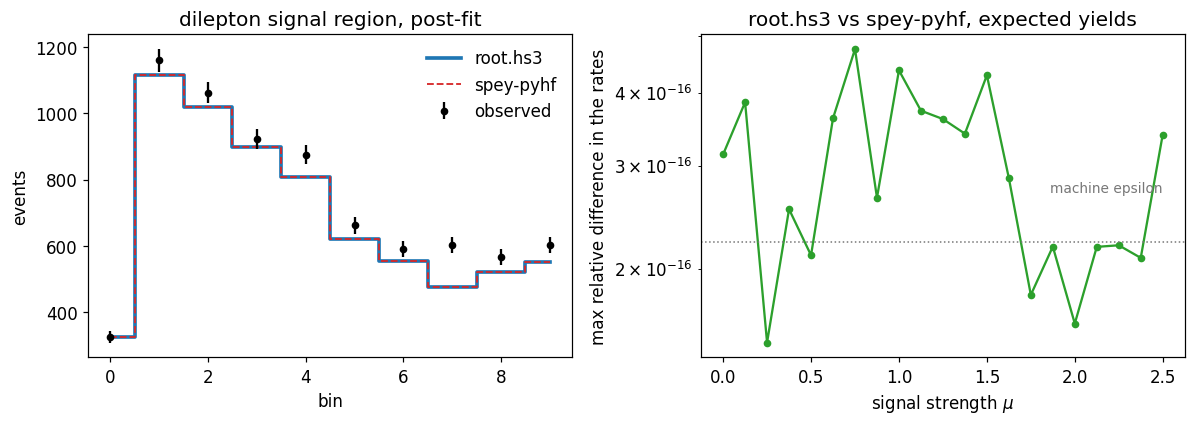

In [20]:
if TOPQ_AVAILABLE and PYHF_TWIN_AVAILABLE:
    fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.0))

    bins = np.arange(view.nbins)
    ours, theirs = expected_rates(nominal)
    axes[0].step(bins, ours, where="mid", lw=2.4, color="#1f77b4", label="root.hs3")
    axes[0].step(bins, theirs, where="mid", lw=1.2, ls="--", color="#d62728",
                 label="spey-pyhf")
    axes[0].errorbar(bins, np.asarray(view.observed_counts), yerr=np.sqrt(view.observed_counts),
                     fmt="ko", ms=4, label="observed")
    axes[0].set_xlabel("bin"); axes[0].set_ylabel("events")
    axes[0].set_title("dilepton signal region, post-fit")
    axes[0].legend(frameon=False)

    scan = np.linspace(0.0, 2.5, 21)
    curve = []
    for mu in scan:
        pars = nominal.copy(); pars[0] = mu
        a, b = expected_rates(pars)
        curve.append(np.max(np.abs(a - b) / b))
    axes[1].semilogy(scan, np.maximum(curve, 1e-17), "o-", color="#2ca02c", ms=4)
    axes[1].axhline(np.finfo(float).eps, color="#777777", ls=":", lw=1.0)
    axes[1].text(scan[-1], np.finfo(float).eps * 1.2, "machine epsilon", ha="right",
                 va="bottom", color="#777777", fontsize=9)
    axes[1].set_xlabel(r"signal strength $\mu$")
    axes[1].set_ylabel("max relative difference in the rates")
    axes[1].set_title("root.hs3 vs spey-pyhf, expected yields")

    plt.tight_layout(); plt.show()
    view.set_parameters(nominal)

### Reinterpretation

The point of the plug-in: take a published likelihood, throw away the signal it was
written for, put a different one in, and ask `spey` for a limit — without ever opening a
`RooFit` workspace. `strip_existing_signal` removes every sample scaled by the parameter
of interest, and `signal_yields` adds a new one.

In [21]:
if TOPQ_AVAILABLE:
    my_signal = [4.0, 12.0, 15.0, 12.0, 9.0, 6.0, 4.0, 3.0, 2.0, 1.0]

    start = time.time()
    reinterpreted = spey.get_backend("root.hs3")(
        workspace=os.path.join(TOPQ, "workspace_dilep_1NF_HS3.json"),
        signal_yields={"model_SR_alt1": my_signal},
        strip_existing_signal=True,
        poi_name="mu",
        analysis="ttgamma-reinterpreted",
    )
    print(f"built in {time.time() - start:.1f} s")

    bkg, sig = reinterpreted.backend._background_and_signal()
    print("\nparameter of interest :", reinterpreted.backend.model.poi.GetName())
    print("signal template       :", np.round(sig, 3))
    print("requested             :", np.asarray(my_signal, dtype=float))
    print("background            :", np.round(bkg, 2))
    print("\nthe published signal has been removed and replaced exactly.")

built in 0.4 s

parameter of interest : mu
signal template       : [ 4. 12. 15. 12.  9.  6.  4.  3.  2.  1.]
requested             : [ 4. 12. 15. 12.  9.  6.  4.  3.  2.  1.]
background            : [ 95.22 224.29 176.87 181.34 207.14 139.99 122.97 100.57  80.02  64.73]

the published signal has been removed and replaced exactly.


In [22]:
if TOPQ_AVAILABLE:
    start = time.time()
    cls = reinterpreted.exclusion_confidence_level()[0]
    print(f"observed CLs at mu = 1 : {cls:.6f}   ({time.time() - start:.1f} s)")

observed CLs at mu = 1 : 0.142042   (59.4 s)


---
## Summary

| what was compared | against | result |
| --- | --- | --- |
| $\log\mathcal{L}(\mu,\theta)$, uncorrelated background | `default.uncorrelated_background` | agrees to $\sim10^{-12}$ |
| $\log\mathcal{L}(\mu,\theta)$, correlated background | `default.correlated_background` | agrees up to the exact Jacobian $\tfrac12\log\det\rho$ |
| $\log\mathcal{L}(\mu)$, no nuisance parameters | `default.poisson` | agrees to $\sim10^{-14}$ |
| Asimov data, both halves | `default.uncorrelated_background` | identical; the auxiliary data follow $\hat\theta$ in both |
| distribution of $t_\mu$ over 2000 toys | `spey`, and $\chi^2_1$ | identical to `spey` to optimiser precision; both track $\chi^2_1$ to the accuracy Wilks' theorem has at these yields |
| expected and observed exclusion, upper limit | `spey` | agree to better than $10^{-5}$ |
| the same workspace read from `.root` and from HS3 | `root.roofit` | bit-for-bit identical |
| ATLAS $t\bar{t}\gamma$ expected yields | the published `pyhf` twin | identical at nominal; $10^{-5}$ relative once nuisances move |
| ATLAS $t\bar{t}\gamma$ $\log\mathcal{L}$ | the published `pyhf` twin | differs, by construction: Poisson vs Gaussian statistics constraint |

Two differences remain, and neither is a defect of the HS3 path:

* **$\sigma_\mu$.** `spey` uses the analytic Hessian of the log-likelihood when a backend
  supplies one, and `RooFit` does not supply one, so `root.hs3` falls back to the
  asymptotic $\sigma_A=|\mu-\mu^\prime|/\sqrt{q_{\mu,A}}$. Two estimators of the same
  quantity, equal only in the asymptotic limit; everything built on the likelihood itself
  agrees.
* **the statistics constraint of the published ATLAS likelihood.** Its HS3 and `pyhf`
  serialisations are not the same likelihood: HS3 asks for a Poisson constraint on the
  Monte-Carlo statistics parameters, `pyhf` always uses a Gaussian one. The rate models are
  identical to machine precision (section 6), which is what a serialisation cross-check can
  legitimately establish.

> Run against `spey` 0.2.8, which fixes the Asimov auxiliary-data convention. Against 0.2.7
> or earlier, sections 2.4, 3 and 4 show differences of a few parts in a thousand up to a
> few per cent, all traceable to that one issue.